<a href="https://colab.research.google.com/github/psh135230-design/BioAI_KU_2026/blob/main/260916_PCA_HVG_2024250170_%EB%B0%B1%EC%88%98%ED%98%84.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PBMC cells through HVG selection and PCA
**BSMS310 | Wednesday, 16 September 2026 | About 45 minutes**

Name: ___백수현___  Student ID: ____2024250170____

How can thousands of gene measurements help us see differences between blood cells?
You will select highly variable genes (HVGs), calculate principal components, and use
gene expression and quality-control measurements to interpret the result.

By the end, explain what a point, an axis, a loading, and an HVG mean in your own words.
Complete the five **Human checkpoints** yourself, in English or Korean.

| Part | Time |
|---|---:|
| Open your copy and set up | 5 min |
| Load PBMC counts and revisit Monday's preprocessing | 8 min |
| Select and inspect HVGs | 10 min |
| Run PCA and read its outputs | 12 min |
| Interpret the plots | 7 min |
| Write your conclusion | 3 min |

## Start in Google Colab

1. Save a copy in your own Drive before editing. Use a **Python 3 CPU** runtime.
2. Run the cells from top to bottom. Pause at each Human checkpoint.
3. If Colab asks you to restart after installation, restart once and continue from the imports.
4. The data downloads automatically. You do not need Monday's file or a Drive mount.

Saved outputs are examples; run the notebook in your own session before drawing conclusions.

In [1]:
# Install the same Scanpy and AnnData versions used in the course.
import subprocess
import sys

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "scanpy==1.11.5", "anndata==0.12.19",
])
print("Installation complete. Continue with the imports below.")

Installation complete. Continue with the imports below.


In [2]:
from pathlib import Path
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from scipy import sparse
from IPython.display import display

sc.settings.verbosity = 0
sc.settings.datasetdir = Path("data")
sc.settings.set_figure_params(dpi=100, facecolor="white", frameon=True)
print("Scanpy:", version("scanpy"), "| AnnData:", version("anndata"))

Scanpy: 1.11.5 | AnnData: 0.12.19


## 1. Start with counts

PBMCs are peripheral blood mononuclear cells. This small 10x Genomics dataset comes
from one healthy donor. The downloaded object contains **2,700 cells** and gene-level
UMI counts. It is already a count matrix, so we do not align FASTQ files today.

Monday's normalization and log1p steps are repeated here so everyone starts from
the same data state. This is the **raw-count PBMC3k object**, not last week's
`pbmc3k_processed` object with precomputed embeddings.

[Dataset documentation](https://scanpy.readthedocs.io/en/stable/generated/scanpy.datasets.pbmc3k.html)

In [3]:
counts = sc.datasets.pbmc3k()
counts.var_names_make_unique()
counts.var["mt"] = counts.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(
    counts, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True,
)
print(f"Downloaded: {counts.n_obs:,} cells x {counts.n_vars:,} genes")
display(counts.obs[["total_counts", "n_genes_by_counts", "pct_counts_mt"]].describe().round(1))

  0%|          | 0.00/5.58M [00:00<?, ?B/s]

Downloaded: 2,700 cells x 32,738 genes


,total_counts,n_genes_by_counts,pct_counts_mt
count,2700.0,2700.0,2700.0
mean,2366.9,847.0,2.2
std,1094.3,282.1,1.2
min,548.0,212.0,0.0
25%,1757.8,690.0,1.5
50%,2197.0,817.0,2.0
75%,2763.0,953.2,2.6
max,15844.0,3422.0,22.6


### A small QC step

We use the classic PBMC tutorial's teaching cutoffs: at least 200 detected genes,
fewer than 2,500 detected genes, and less than 5% mitochondrial counts per cell.
Keep genes detected in at least three retained cells. These cutoffs are examples
for this dataset, not universal rules for other tissues or experiments.

The QC columns below describe the counts **before gene filtering and normalization**.

In [4]:
keep = (
    (counts.obs["n_genes_by_counts"] >= 200)
    & (counts.obs["n_genes_by_counts"] < 2500)
    & (counts.obs["pct_counts_mt"] < 5)
)
adata = counts[keep].copy()
sc.pp.filter_genes(adata, min_cells=3)

# Preserve the retained raw counts before changing X.
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

print(f"After QC: {adata.n_obs:,} cells x {adata.n_vars:,} genes")
print("X: log1p of counts normalized to 10,000 per cell")
print("layers['counts']: retained raw UMI counts")
shown = np.flatnonzero(adata.layers["counts"][0].toarray().ravel())[:8]
display(pd.DataFrame({
    "raw count": adata.layers["counts"][0, shown].toarray().ravel(),
    "log-normalized X": adata.X[0, shown].toarray().ravel(),
}, index=adata.var_names[shown]))

After QC: 2,638 cells x 13,656 genes
X: log1p of counts normalized to 10,000 per cell
layers['counts']: retained raw UMI counts


,raw count,log-normalized X
index,,
MRPL20,1.0,1.635873
RPL22,1.0,1.635873
TNFRSF25,2.0,2.226555
EFHD2,1.0,1.635873
NECAP2,1.0,1.635873
AKR7A2,1.0,1.635873
CAPZB,1.0,1.635873
RPL11,41.0,5.138686


### Human checkpoint 1 | Keep track of the matrix

Write the number of retained cells and genes. Explain why we should **not** run
`normalize_total` and `log1p` again on this `adata.X`. Where can you still find counts?

**My answer:** After QC: 2,638 cells x 13,656 genes/ 다시 정규화와 로그를 취하면 분산이 작아져 이후 PCA 등의 시각화 때 무의미한 결과가 나온다. / adata.layers["counts"]로 사본 저장했으므로 불러올 수 있다.

_

## 2. Which genes vary more than expected?

A highly expressed gene need not distinguish cells. HVG selection looks for
variation relative to genes with similar mean expression. We use `flavor="seurat"`,
which expects **log-normalized input**. Select HVGs **before scaling**.

An HVG is not automatically a cell-type marker, a disease gene, or a statistically
significant difference between groups. Its selection depends on these cells and
this preprocessing method. The choice of 2,000 genes is a starting setting.

[HVG function and input requirements](https://scanpy.readthedocs.io/en/stable/generated/scanpy.pp.highly_variable_genes.html)

Selected HVGs: 2,000; genes retained in adata: 13,656


,means,dispersions,dispersions_norm
index,,,
DOK3,0.278,5.838,8.046
ARVCF,0.133,5.807,7.985
YPEL2,0.248,5.806,7.983
UBE2D4,0.260,5.780,7.931
FAM210B,0.271,5.728,7.829
CTB-113I20.2,0.129,5.654,7.684
GBGT1,0.178,5.626,7.629
LRRIQ3,0.100,5.441,7.263
MTIF2,0.224,5.374,7.132


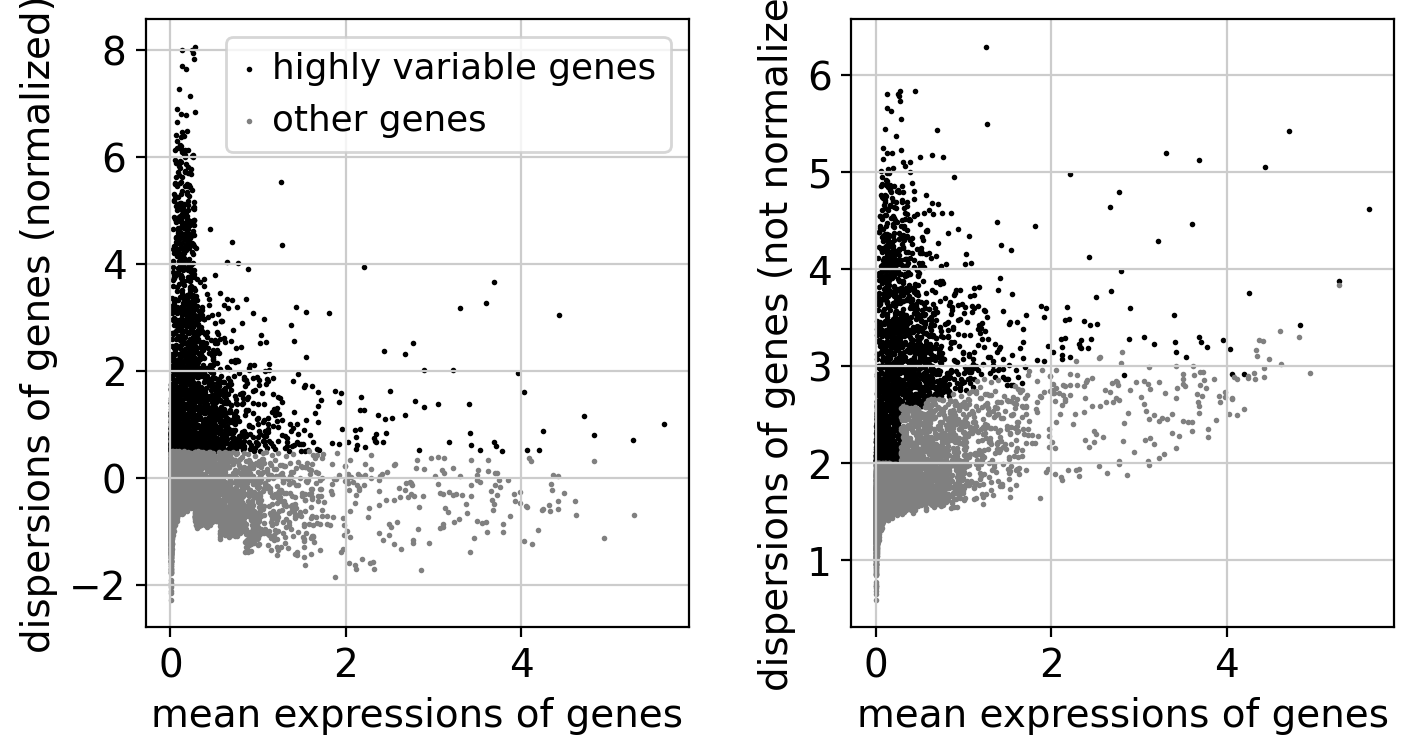

In [5]:
N_HVG = 2000

sc.pp.highly_variable_genes(
    adata, flavor="seurat", n_top_genes=N_HVG, subset=False,
)
hvg_table = (
    adata.var.loc[adata.var["highly_variable"], ["means", "dispersions", "dispersions_norm"]]
    .sort_values("dispersions_norm", ascending=False)
)
print(f"Selected HVGs: {len(hvg_table):,}; genes retained in adata: {adata.n_vars:,}")
display(hvg_table.head(10).round(3))
sc.pl.highly_variable_genes(adata, show=False)
plt.show()

In [6]:
# Compare gene lists produced by two different questions.
mean_log_expression = pd.Series(
    np.asarray(adata.X.mean(axis=0)).ravel(), index=adata.var_names,
)
top_expression = mean_log_expression.sort_values(ascending=False).head(10)
display(pd.DataFrame({
    "Highest mean log-expression": top_expression.index,
    "Highest normalized dispersion among HVGs": hvg_table.head(10).index,
}))
print("Genes shared by the two top-10 lists:", len(set(top_expression.index) & set(hvg_table.head(10).index)))

,Highest mean log-expression,Highest normalized dispersion among HVGs
0,MALAT1,DOK3
1,TMSB4X,ARVCF
2,B2M,YPEL2
3,RPL10,UBE2D4
4,RPL13A,FAM210B
5,RPL13,CTB-113I20.2
6,RPS2,GBGT1
7,RPS6,LRRIQ3
8,RPS18,MTIF2
9,RPL11,TTC8


Genes shared by the two top-10 lists: 0


### Human checkpoint 2 | HVG is not the same as high expression

Choose one gene from each list. Use the plot or table to explain why selecting
highly expressed genes and selecting HVGs answer different questions.
What does one dot represent in the HVG plot?

**My answer:** MALAT1은 가장 높은 발현량, DOK3는 HVG로 뽑혔는데 서로를 다른 표의 열에서 찾아보면 보이지 않는다. 이는 세포마다 특이적으로 발현하는 유전자는 차이가 있으며 추측하기로는 세포가 공통적으로 생존에 필요한 유전자 발현량이 가장 높을 것이고 세포 특성에 따라 발현하는 유전자는 비교적 작게 발현될 것이다./ HVG plot에서 한 점은 유전자 한 타입을 의미한다.

_

## 3. Build a compact description of each cell

PCA finds directions that capture variation in the matrix it receives. A **cell score**
is a cell's coordinate on a principal component. A **gene loading** tells us how a
gene contributes to that direction. PCA does not know cell types or assign labels.

Make a separate object containing HVGs, then scale each gene across cells. Scaling
puts genes on comparable scales; clipping at 10 limits extreme positive scaled values.
This small HVG matrix can fit in memory as a dense array. Keep the full
log-normalized `adata` for plotting gene expression later.

**Order: counts → QC → normalize → log1p → HVG → scale → PCA.**

In [7]:
pca_data = adata[:, adata.var["highly_variable"]].copy()
if sparse.issparse(pca_data.X):
    pca_data.X = pca_data.X.toarray()
sc.pp.scale(pca_data, zero_center=True, max_value=10)
sc.pp.pca(
    pca_data, n_comps=30, svd_solver="arpack", random_state=0, mask_var=None,
)

# Match the cell order before using these coordinates on the full gene object.
assert adata.obs_names.equals(pca_data.obs_names)
adata.obsm["X_pca"] = pca_data.obsm["X_pca"].copy()

display(pd.DataFrame({
    "Output": ["Scaled input", "Cell scores", "Gene loadings"],
    "Location": ["pca_data.X", "pca_data.obsm['X_pca']", "pca_data.varm['PCs']"],
    "Shape": [str(pca_data.X.shape), str(pca_data.obsm["X_pca"].shape), str(pca_data.varm["PCs"].shape)],
}))

,Output,Location,Shape
0,Scaled input,pca_data.X,"(2638, 2000)"
1,Cell scores,pca_data.obsm['X_pca'],"(2638, 30)"
2,Gene loadings,pca_data.varm['PCs'],"(2000, 30)"


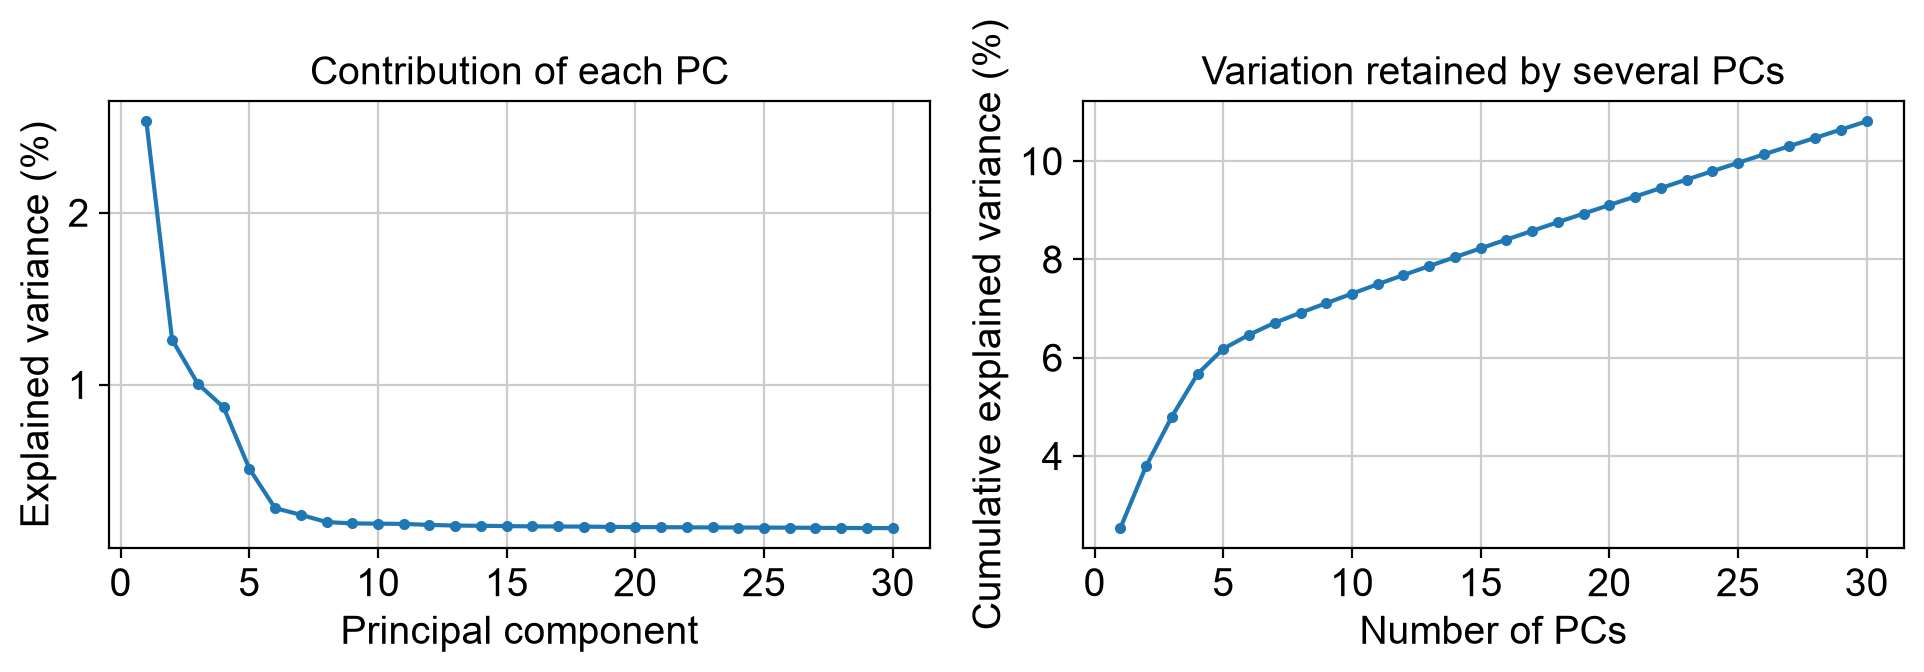

PC1 + PC2 explain 3.8% of variation in the scaled HVG input.


In [ ]:
variance = pca_data.uns["pca"]["variance_ratio"]
pcs = np.arange(1, len(variance) + 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(pcs, 100 * variance, "o-", markersize=3)
axes[0].set(xlabel="Principal component", ylabel="Explained variance (%)", title="Contribution of each PC")
axes[1].plot(pcs, 100 * np.cumsum(variance), "o-", markersize=3)
axes[1].set(xlabel="Number of PCs", ylabel="Cumulative explained variance (%)", title="Variation retained by several PCs")
fig.tight_layout()
plt.show()
print(f"PC1 + PC2 explain {100 * variance[:2].sum():.1f}% of variation in the scaled HVG input.")

### Human checkpoint 3 | Read the PCA outputs

What do the rows represent in the cell-score matrix and in the loading matrix?
How much variance do PC1 and PC2 retain together? Explain why the two-dimensional
plot cannot show all differences between cells.

**My answer:** cell-score는 세포가 pc에 대해 갖는 값, loading 은 유전자의 pc에 대한 기여도/ PC1 + PC2 = 3.8% / 세포의 분포에 대한 정보가 주성분 축을 2개로 줄이며, 다수 소실되었기 때문이다.
_

## 4. Look at the same coordinates in several ways

Each point below is **one cell**. Only the color changes between panels.
First inspect total counts and mitochondrial percentage. Then inspect three example
genes used in the PBMC tutorial. Gene colors show **log-normalized expression from
the full `adata.X`**, not scaled values from `pca_data.X`.

Expression patterns can suggest a biological explanation, but one gene or a visible
cloud of points is not enough to establish a cell identity. This object has no
reference cell-type labels, and one donor cannot support a between-donor comparison.

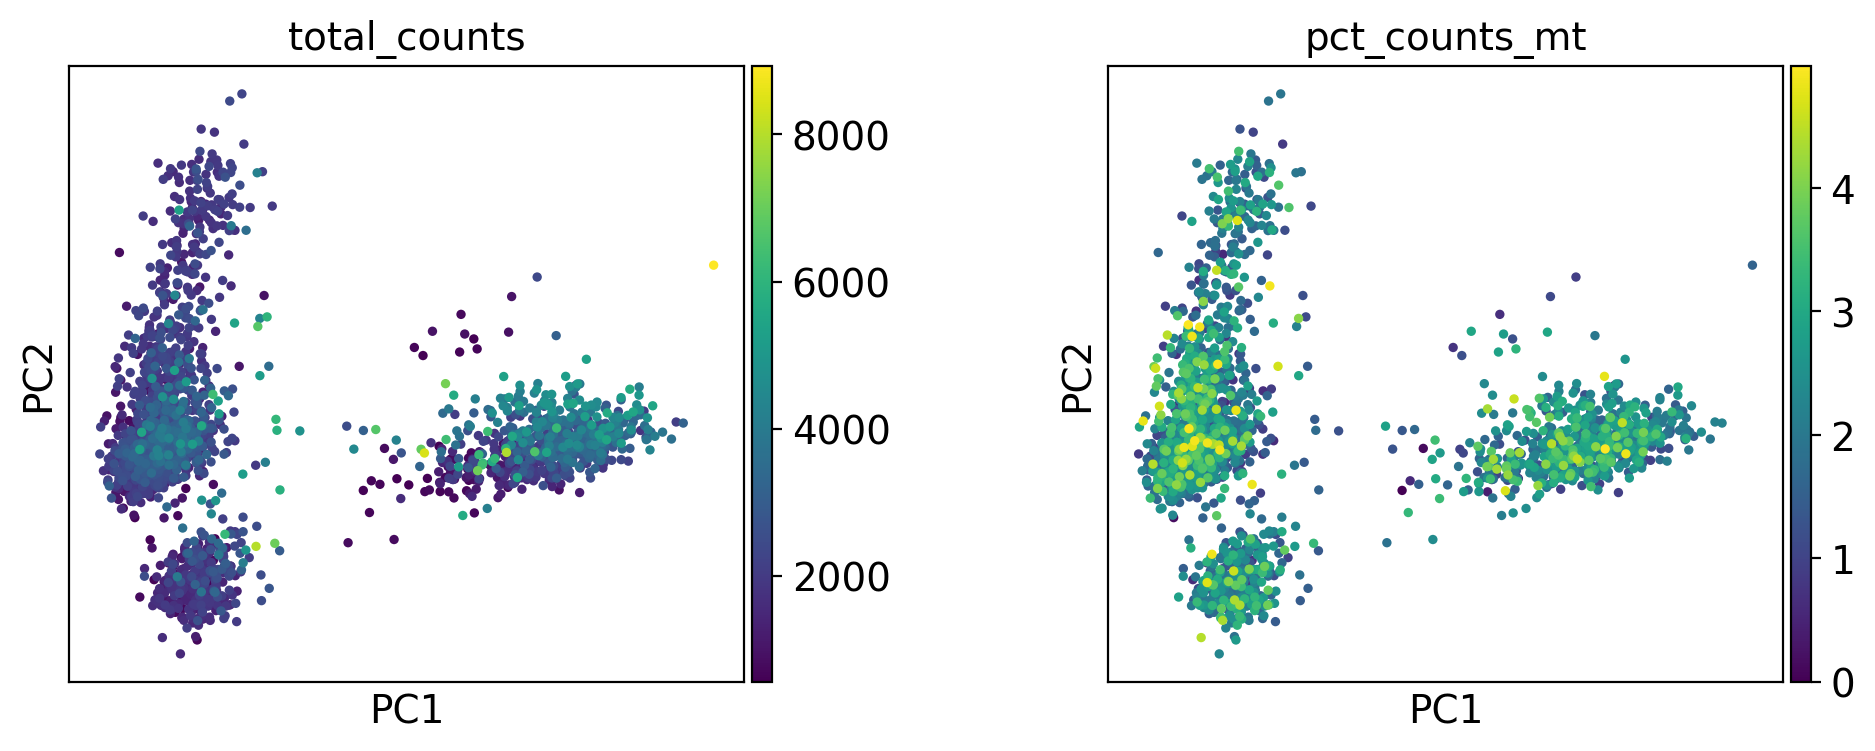

In [8]:
sc.pl.pca(
    adata, color=["total_counts", "pct_counts_mt"], use_raw=False,
    ncols=2, wspace=0.4, show=False,
)
plt.show()

,highly_variable,dispersions_norm
index,,
CD3D,False,-0.104521
MS4A1,True,0.628634
NKG7,True,2.312801


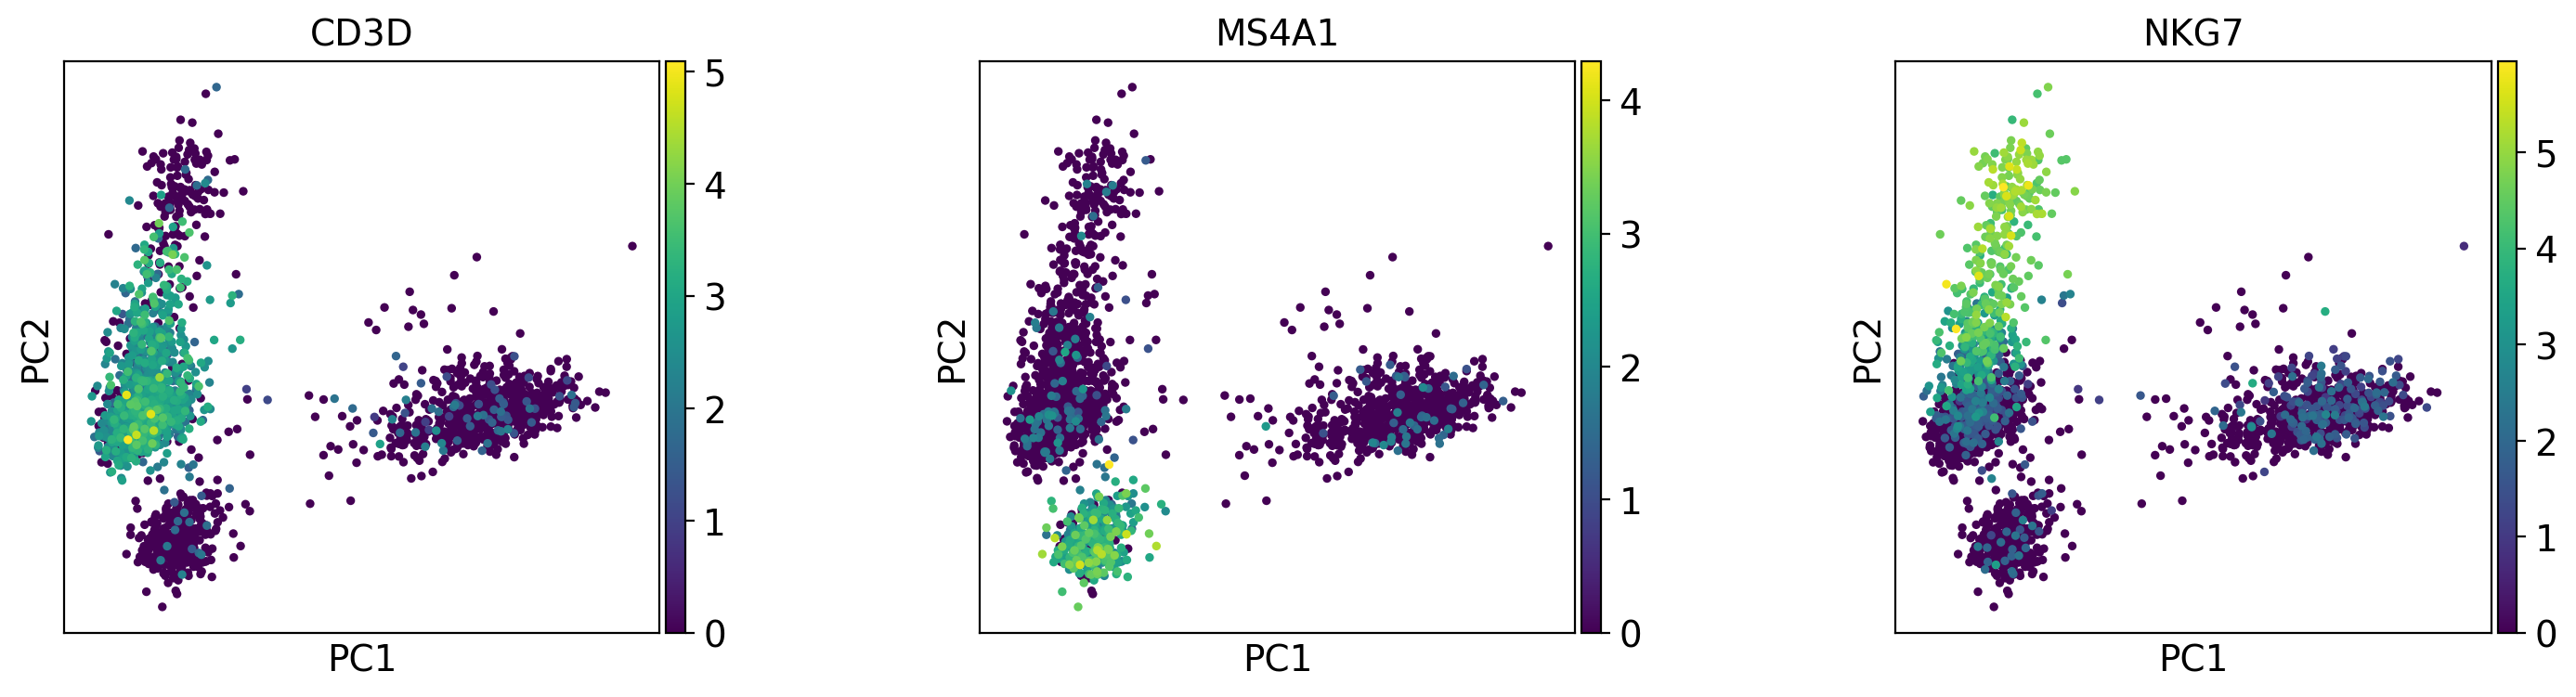

In [9]:
example_genes = ["CD3D", "MS4A1", "NKG7"]
display(adata.var.loc[example_genes, ["highly_variable", "dispersions_norm"]])
sc.pl.pca(
    adata, color=example_genes, use_raw=False, ncols=3,
    cmap="viridis", wspace=0.4, show=False,
)
plt.show()

### Human checkpoint 4 | Observation before explanation

Describe one pattern in the gene-colored plots and one pattern in the QC-colored
plots. Cite the panel and the part of the plot you mean. Give one possible explanation
and one additional check needed before accepting it. Correlation alone is not proof
of a technical artifact or a biological cause.

**My answer:** 유전자 플롯에서 CD3D는 왼쪽 큰 덩어리 중앙에 구배를 보인다. qc 플롯에서는 pc1 기준으로 오른쪽으로 갈수록 umi 양이 늘어났음을 알 수 있다. / CD3D라는 유전자는 hvg로 선별되지 않았음에도 유전자 플롯에서 특정한 그룹 패턴을 보인다. 그렇다면 해당 유전자가 해당 세포 데이터셋에서는 비교적 고르게 발현되나, 다른 데이터셋에서는 hvg로 선별될 수 있다. 따라서 해당 유전자에 대해서는 다양한 세포 그룹을 기반으로 한 데이터가 더 필요하다.

_

### Which genes contribute to PC1 and PC2?

The next plot shows genes with the largest **absolute** loadings and preserves the
positive or negative sign of each contribution. The sign shows the direction of a contribution,
not whether a gene is beneficial or harmful. An entire PCA axis can reverse sign
without changing the geometry of the result.

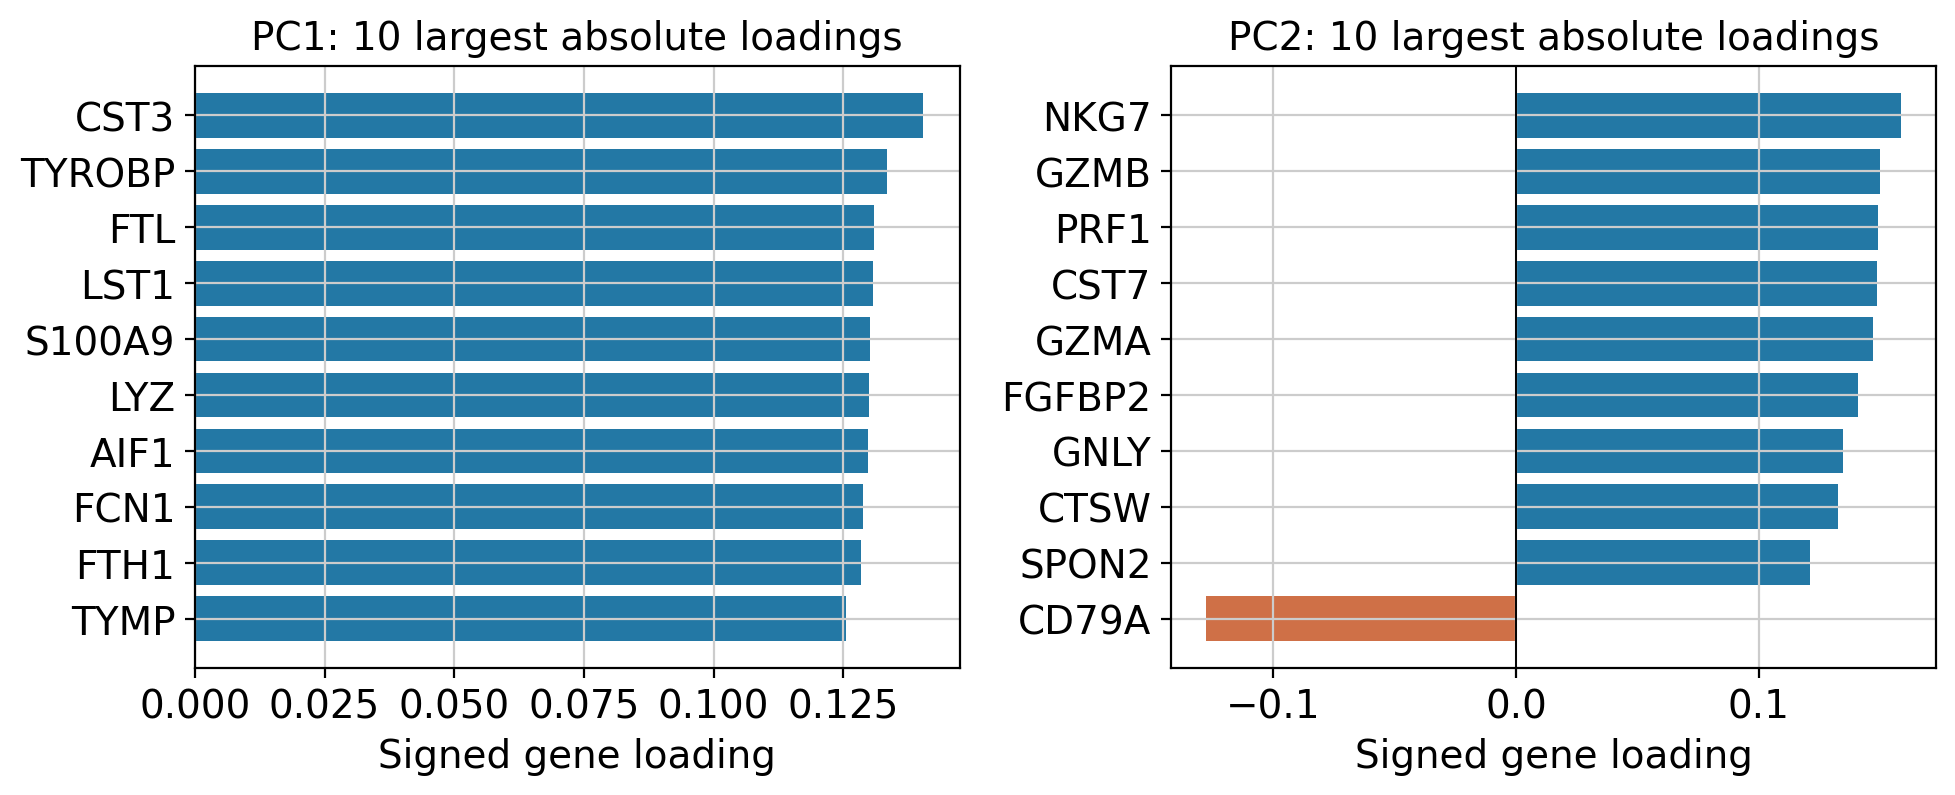

In [10]:
loadings = pd.DataFrame(
    pca_data.varm["PCs"], index=pca_data.var_names,
    columns=[f"PC{i + 1}" for i in range(pca_data.varm["PCs"].shape[1])],
)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, pc in zip(axes, ["PC1", "PC2"]):
    selected = loadings[pc].abs().nlargest(10).index
    values = loadings.loc[selected, pc].sort_values()
    ax.barh(values.index, values.values, color=np.where(values.values >= 0, "#2378a5", "#cf7047"))
    ax.axvline(0, color="black", linewidth=0.7)
    ax.set(title=f"{pc}: 10 largest absolute loadings", xlabel="Signed gene loading")
fig.tight_layout()
plt.show()

### Try one gene of your choice

Replace `GENE` with a gene symbol from the HVG table or loading plot. Predict where
it will be expressed, then run the cell. You can choose a retained gene that was not
selected as an HVG because we preserved the full gene object.

DOK3 | Selected as an HVG: True


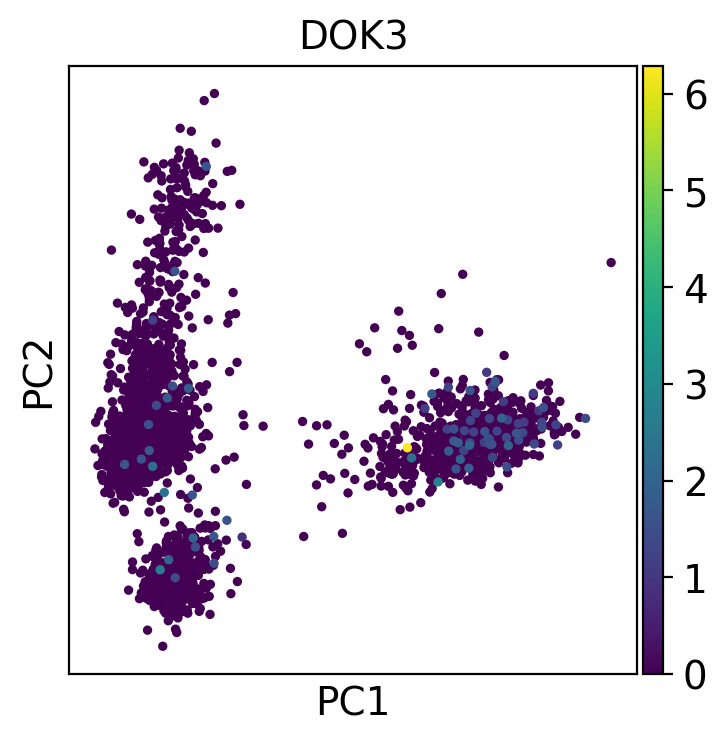

In [11]:
GENE = "DOK3"  # Change this gene, then rerun this cell.

if GENE not in adata.var_names:
    print("Gene not found. Copy an exact gene symbol from the displayed tables.")
else:
    print(GENE, "| Selected as an HVG:", bool(adata.var.loc[GENE, "highly_variable"]))
    sc.pl.pca(adata, color=GENE, use_raw=False, cmap="viridis", show=False)
    plt.show()

### Human checkpoint 5 | Your conclusion

1. The gene I inspected was __. I predicted ___ and observed ___.
2. PC___ may reflect ___ because ___.
3. I would check ___ before assigning a biological interpretation.

**My answer:**
1. The gene I inspected was _DOK3_. I predicted __it would be in a specific group in the plot_ and observed _that the gene was nearly visible in it__.
2. PC_2_ may reflect __**the difference between the small groups on the left side of the plot**_ because __**NKG7 is high at the top and MS4A1 is high at the bottom**_.
3. I would check __**whether NKG7 and MS4A1 really have large PC2 loadings with opposite signs, and whether the top and bottom cells differ in total_counts**_ before assigning a biological interpretation.

## Optional comparison | About 5 minutes

If time allows, compare your checkpoint 4 or 5 with a classmate. Find one observation
you agree on and one explanation for which you need more evidence. Show the figure
that supports each statement.

For an independent extension, change `N_HVG` from 2,000 to 1,000 and rerun from
HVG selection onward. Record the actual HVG count, PC1 + PC2 variance percentage,
and one expression pattern that stays similar or changes. PCA signs can reverse;
compare patterns rather than left-versus-right positions alone. The variance
percentages describe different input feature sets, so a larger value does not by
itself identify the better analysis.

## Before you finish

- Confirm that you ran the cells in order and wrote your own checkpoint answers.
- Save your copy with a name that includes your student ID and name.
- If you used AI assistance, record the tool, the question you asked, one suggestion
  you checked, and what the data showed. If you did not use AI, write "Not used".

**AI use and verification:**

_ claude opus 5.0


## References

- [Scanpy PBMC3k dataset](https://scanpy.readthedocs.io/en/stable/generated/scanpy.datasets.pbmc3k.html)
- [Scanpy PBMC preprocessing tutorial](https://scanpy.readthedocs.io/en/stable/tutorials/basics/clustering-2017.html)
- [Scanpy HVG selection](https://scanpy.readthedocs.io/en/stable/generated/scanpy.pp.highly_variable_genes.html)
- [Scanpy PCA](https://scanpy.readthedocs.io/en/stable/generated/scanpy.pp.pca.html)